In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
CSV_FILE = (
    r"C:\Users\arshi\OneDrive\Desktop\CLC-02\Group A Deadline-21 Nov 26"
    r" Model_CLC_02 - Copy of Master.csv"
)

df = pd.read_csv(CSV_FILE, encoding="utf-8-sig")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (335, 10)
Columns: ['S No.', 'Country', 'City', 'Company', 'Contact', 'Google Maps', 'Category', 'Rating', 'Review', 'Clean Category']


,S No.,Country,City,Company,Contact,Google Maps,Category,Rating,Review,Clean Category
0,1,India,Ahmedabad,Kabira Institute of Computer,+91 70450 58912,https://www.google.com/maps/search/?api=1&quer...,Computer Training,4.9,135,Educational institution
1,2,India,Ahmedabad,Anik Computers and Education,+91 94263 53863,https://www.google.com/maps/search/?api=1&quer...,Computer Training,5.0,70,Educational institution
2,3,India,Ahmedabad,Jade Education and Training,+91 88791 52644,https://www.google.com/maps/search/?api=1&quer...,Computer Training,5.0,528,Educational institution
3,4,India,Ahmedabad,New Pramukh Institute of Information Technology,+91 88791 68790,https://www.google.com/maps/search/?api=1&quer...,Technology Training,4.9,300,Educational institution
4,5,India,Ahmedabad,Sultan Ahmed Computer Centre,079 2550 6264,https://www.google.com/maps/search/?api=1&quer...,Computer Training,4.6,152,Educational institution


In [3]:
required_columns = ["Company", "Country", "Rating", "Review"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df["Review"] = pd.to_numeric(
    df["Review"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

if df["Rating"].dropna().lt(0).any() or df["Rating"].dropna().gt(5).any():
    raise ValueError("Ratings must be between 0 and 5.")
if df["Review"].dropna().lt(0).any():
    raise ValueError("Review counts cannot be negative.")

print("Total businesses:", len(df))
print("Missing ratings:", df["Rating"].isna().sum())
print("Missing review counts:", df["Review"].isna().sum())

Total businesses: 335
Missing ratings: 0
Missing review counts: 0


In [4]:
country_clean = df["Country"].astype("string").str.strip().str.casefold()

df["Business_Classification"] = np.select(
    [
        country_clean.eq("india"),
        country_clean.notna() & country_clean.ne("")
    ],
    ["Indian", "Foreign"],
    default="Unknown"
)

print(df["Business_Classification"].value_counts(dropna=False))

Business_Classification
Indian     274
Foreign     61
Name: count, dtype: int64


In [5]:
# Businesses with both rating and review count equal to zero, or missing values,
# are kept in the final dataset but excluded from review scoring/model training.
valid_review_mask = (
    df["Rating"].notna()
    & df["Review"].notna()
    & ~((df["Rating"] == 0) & (df["Review"] == 0))
)

model_df = df.loc[valid_review_mask].copy()

print("Businesses with usable review data:", len(model_df))
print("Businesses without usable review data:", len(df) - len(model_df))

Businesses with usable review data: 331
Businesses without usable review data: 4


In [6]:
model_df["Log_Review_Count"] = np.log1p(model_df["Review"])

min_reviews = model_df["Log_Review_Count"].min()
max_reviews = model_df["Log_Review_Count"].max()

if max_reviews > min_reviews:
    model_df["Normalized_Review_Count"] = (
        (model_df["Log_Review_Count"] - min_reviews)
        / (max_reviews - min_reviews)
    )
else:
    model_df["Normalized_Review_Count"] = 0.0

model_df["Normalized_Rating"] = model_df["Rating"] / 5

model_df["Review_Performance_Score"] = (
    0.60 * model_df["Normalized_Review_Count"]
    + 0.40 * model_df["Normalized_Rating"]
)

display(model_df[
    ["Company", "Country", "Rating", "Review",
     "Normalized_Review_Count", "Normalized_Rating",
     "Review_Performance_Score"]
].head(10))

,Company,Country,Rating,Review,Normalized_Review_Count,Normalized_Rating,Review_Performance_Score
0,Kabira Institute of Computer,India,4.9,135,0.456382,0.98,0.665829
1,Anik Computers and Education,India,5.0,70,0.386081,1.00,0.631648
2,Jade Education and Training,India,5.0,528,0.603299,1.00,0.76198
3,New Pramukh Institute of Information Technology,India,4.9,300,0.54231,0.98,0.717386
4,Sultan Ahmed Computer Centre,India,4.6,152,0.469121,0.92,0.649473
5,Microshine Computer Academy,India,4.9,142,0.46181,0.98,0.669086
6,CDAC Computer Education,India,4.9,198,0.497553,0.98,0.690532
7,Akshar Compusoft Education,India,4.8,122,0.445515,0.96,0.651309
8,Genius Computer,India,4.7,79,0.398989,0.94,0.615394
9,Sigma Computer Education,India,4.9,1433,0.71116,0.98,0.818696


In [7]:
q1 = model_df["Review_Performance_Score"].quantile(0.25)
q3 = model_df["Review_Performance_Score"].quantile(0.75)

model_df["Priority"] = np.select(
    [
        model_df["Review_Performance_Score"] <= q1,
        model_df["Review_Performance_Score"] <= q3
    ],
    ["Low", "Medium"],
    default="High"
)

print("Review priority counts:")
print(model_df["Priority"].value_counts())
print("\nScore thresholds:")
print("Low / Medium boundary (25th percentile):", round(q1, 4))
print("Medium / High boundary (75th percentile):", round(q3, 4))

Review priority counts:
Priority
Medium    165
High       83
Low        83
Name: count, dtype: int64

Score thresholds:
Low / Medium boundary (25th percentile): 0.5527
Medium / High boundary (75th percentile): 0.7263


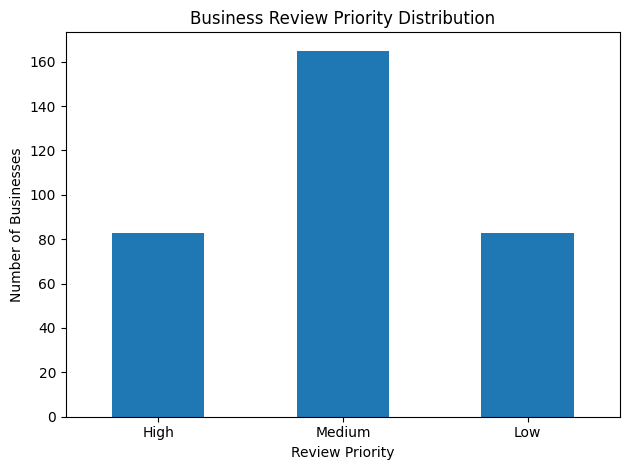

In [8]:
priority_counts = (
    model_df["Priority"]
    .value_counts()
    .reindex(["High", "Medium", "Low"], fill_value=0)
)

priority_counts.plot(kind="bar", rot=0)
plt.title("Business Review Priority Distribution")
plt.xlabel("Review Priority")
plt.ylabel("Number of Businesses")
plt.tight_layout()
plt.show()

In [9]:
features = ["Normalized_Review_Count", "Normalized_Rating"]
X = model_df[features]
y = model_df["Priority"]

class_counts = y.value_counts()
if len(class_counts) < 2 or class_counts.min() < 2:
    raise ValueError(
        "There are not enough records in each priority class for a stratified "
        "train/test split. Check the dataset and priority distribution."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

review_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=2000))
])

review_model.fit(X_train, y_train)
y_pred = review_model.predict(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Training records: 264
Testing records: 67
Accuracy: 0.9552

Classification Report:
              precision    recall  f1-score   support

        High       0.94      1.00      0.97        17
         Low       1.00      0.88      0.94        17
      Medium       0.94      0.97      0.96        33

    accuracy                           0.96        67
   macro avg       0.96      0.95      0.95        67
weighted avg       0.96      0.96      0.95        67



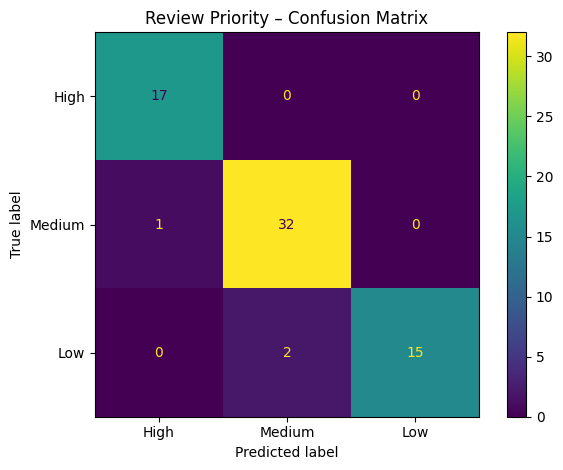

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=["High", "Medium", "Low"])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["High", "Medium", "Low"]
)
disp.plot()
plt.title("Review Priority – Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
model_df["Predicted_Priority"] = review_model.predict(X)
model_df["Predicted_Probability"] = review_model.predict_proba(X).max(axis=1)

display(model_df[
    ["Company", "Country", "Rating", "Review",
     "Review_Performance_Score", "Priority",
     "Predicted_Priority", "Predicted_Probability"]
].head(10))

,Company,Country,Rating,Review,Review_Performance_Score,Priority,Predicted_Priority,Predicted_Probability
0,Kabira Institute of Computer,India,4.9,135,0.665829,Medium,Medium,0.927033
1,Anik Computers and Education,India,5.0,70,0.631648,Medium,Medium,0.951819
2,Jade Education and Training,India,5.0,528,0.76198,High,High,0.815779
3,New Pramukh Institute of Information Technology,India,4.9,300,0.717386,Medium,Medium,0.605260
4,Sultan Ahmed Computer Centre,India,4.6,152,0.649473,Medium,Medium,0.947474
5,Microshine Computer Academy,India,4.9,142,0.669086,Medium,Medium,0.919060
6,CDAC Computer Education,India,4.9,198,0.690532,Medium,Medium,0.829266
7,Akshar Compusoft Education,India,4.8,122,0.651309,Medium,Medium,0.948048
8,Genius Computer,India,4.7,79,0.615394,Medium,Medium,0.928865
9,Sigma Computer Education,India,4.9,1433,0.818696,High,High,0.981717


In [12]:
# Preserve every original business row, including those without review data.
final_output = df.copy()

new_columns = [
    "Log_Review_Count",
    "Normalized_Review_Count",
    "Normalized_Rating",
    "Review_Performance_Score",
    "Priority",
    "Predicted_Priority",
    "Predicted_Probability"
]

for col in new_columns:
    final_output[col] = np.nan

final_output["Priority"] = "No Review Data"
final_output["Predicted_Priority"] = "No Review Data"

for col in new_columns:
    if col in model_df.columns:
        final_output.loc[model_df.index, col] = model_df[col]

print("Final output rows:", len(final_output))
print("\nPriority counts including businesses without review data:")
print(final_output["Priority"].value_counts(dropna=False))
display(final_output.head())

Final output rows: 335

Priority counts including businesses without review data:
Priority
Medium            165
High               83
Low                83
No Review Data      4
Name: count, dtype: int64


,S No.,Country,City,Company,Contact,Google Maps,Category,Rating,Review,Clean Category,Business_Classification,Log_Review_Count,Normalized_Review_Count,Normalized_Rating,Review_Performance_Score,Priority,Predicted_Priority,Predicted_Probability
0,1,India,Ahmedabad,Kabira Institute of Computer,+91 70450 58912,https://www.google.com/maps/search/?api=1&quer...,Computer Training,4.9,135,Educational institution,Indian,4.912655,0.456382,0.98,0.665829,Medium,Medium,0.927033
1,2,India,Ahmedabad,Anik Computers and Education,+91 94263 53863,https://www.google.com/maps/search/?api=1&quer...,Computer Training,5.0,70,Educational institution,Indian,4.262680,0.386081,1.00,0.631648,Medium,Medium,0.951819
2,3,India,Ahmedabad,Jade Education and Training,+91 88791 52644,https://www.google.com/maps/search/?api=1&quer...,Computer Training,5.0,528,Educational institution,Indian,6.270988,0.603299,1.00,0.761980,High,High,0.815779
3,4,India,Ahmedabad,New Pramukh Institute of Information Technology,+91 88791 68790,https://www.google.com/maps/search/?api=1&quer...,Technology Training,4.9,300,Educational institution,Indian,5.707110,0.542310,0.98,0.717386,Medium,Medium,0.605260
4,5,India,Ahmedabad,Sultan Ahmed Computer Centre,079 2550 6264,https://www.google.com/maps/search/?api=1&quer...,Computer Training,4.6,152,Educational institution,Indian,5.030438,0.469121,0.92,0.649473,Medium,Medium,0.947474


In [13]:
# Complete review analysis output
final_output.to_csv("CLC_02_Final_Review_Analysis.csv", index=False)

# Separate priority files
for priority in ["High", "Medium", "Low", "No Review Data"]:
    priority_df = final_output[final_output["Priority"] == priority].copy()
    filename = f"CLC_02_{priority.replace(' ', '_')}_Priority.csv"
    priority_df.to_csv(filename, index=False)
    print(f"{filename}: {len(priority_df)} businesses")

# Separate Indian and Foreign business files
indian_df = final_output[final_output["Business_Classification"] == "Indian"].copy()
foreign_df = final_output[final_output["Business_Classification"] == "Foreign"].copy()

indian_df.to_csv("CLC_02_Indian_Businesses.csv", index=False)
foreign_df.to_csv("CLC_02_Foreign_Businesses.csv", index=False)

print("CLC_02_Indian_Businesses.csv:", len(indian_df), "businesses")
print("CLC_02_Foreign_Businesses.csv:", len(foreign_df), "businesses")

PermissionError: [Errno 13] Permission denied: 'CLC_02_High_Priority.csv'

In [ ]:
for filename in [
    "CLC_02_Final_Review_Analysis.csv",
    "CLC_02_High_Priority.csv",
    "CLC_02_Medium_Priority.csv",
    "CLC_02_Low_Priority.csv",
    "CLC_02_No_Review_Data_Priority.csv",
    "CLC_02_Indian_Businesses.csv",
    "CLC_02_Foreign_Businesses.csv"
]:
    check_df = pd.read_csv(filename)
    print(f"{filename}: {len(check_df)} rows")

print("\nAll review analysis CSV exports verified.")

In [ ]:
# ONE SHARED PRIORITY PER CLEANED CATEGORY

category_scores = (
    model_df.groupby("Clean Category")
    .agg(
        Average_Review_Score=("Review_Performance_Score", "mean"),
        Business_Count=("Company", "count")
    )
    .reset_index()
)

# Rank cleaned categories by average review score
category_scores["Category_Rank"] = (
    category_scores["Average_Review_Score"]
    .rank(method="first", ascending=False)
)

# Assign one priority to each cleaned category
n_categories = len(category_scores)

category_scores["Category_Priority"] = np.select(
    [
        category_scores["Category_Rank"] <= n_categories / 3,
        category_scores["Category_Rank"] <= 2 * n_categories / 3
    ],
    ["High", "Medium"],
    default="Low"
)

# Map the same priority to every business in that category
priority_map = category_scores.set_index(
    "Clean Category"
)["Category_Priority"]

model_df["Category_Priority"] = (
    model_df["Clean Category"].map(priority_map)
)

# Verify uniqueness
assert category_scores["Clean Category"].is_unique

print("Category classification completed.")
display(
    category_scores.sort_values(
        "Average_Review_Score",
        ascending=False
    )
)

In [ ]:
category_scores.to_csv(
    "CLC_02_Cleaned_Category_Priority_Mapping.csv",
    index=False
)

for priority in ["High", "Medium", "Low"]:
    categories = sorted(
        category_scores.loc[
            category_scores["Category_Priority"] == priority,
            "Clean Category"
        ].dropna().unique()
    )

    print(f"\n{priority} Priority Categories:")
    print(", ".join(categories))

In [ ]:
# Calculate category priority thresholds

category_scores = category_scores.sort_values(
    "Average_Review_Score",
    ascending=False
).reset_index(drop=True)

n = len(category_scores)

# Divide categories into three priority groups
high_count = int(n / 3)
medium_count = int(2 * n / 3) - high_count

# Get actual score boundaries
high_threshold = category_scores.loc[
    high_count - 1, "Average_Review_Score"
]

medium_threshold = category_scores.loc[
    high_count + medium_count - 1, "Average_Review_Score"
]

print("CATEGORY PRIORITY THRESHOLDS")
print("--------------------------------")

print(
    f"High Priority: Average Review Score >= {high_threshold:.4f}"
)

print(
    f"Medium Priority: Average Review Score >= {medium_threshold:.4f} "
    f"and < {high_threshold:.4f}"
)

print(
    f"Low Priority: Average Review Score < {medium_threshold:.4f}"
)

# No Review Data condition
print(
    "No Review Data: Both Rating and Review count are 0"
)

In [ ]:
# Get all unique cleaned categories
all_categories = set(
    df["Clean Category"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

# Categories assigned to each priority
high_categories = {
    "Dentist",
    "Medical laboratory",
    "Physical rehabilitation center"
}

medium_categories = {
    "Clinic",
    "Educational institution",
    "Hospital"
}

low_categories = {
    "Charity",
    "Pharmacy",
    "Psychiatrist",
    "Software company"
}

assigned_categories = (
    high_categories | medium_categories | low_categories
)

# Find missing and extra categories
missing_categories = all_categories - assigned_categories
extra_categories = assigned_categories - all_categories

print("Total Cleaned Categories:", len(all_categories))
print("Total Assigned Categories:", len(assigned_categories))

print("\nMissing Categories:")
print(sorted(missing_categories) if missing_categories else "None")

print("\nExtra Categories:")
print(sorted(extra_categories) if extra_categories else "None")

print("\nAll categories covered:", all_categories == assigned_categories)